# 03 — RFM & Customer Segmentation

Perform RFM scoring and compare K-Means, Agglomerative Clustering and DBSCAN.

The final segment names must be assigned only after inspecting actual cluster profiles.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

DATA = ROOT / "data" / "processed" / "customer_features.csv"
df = pd.read_csv(DATA)
df.head()


,CustomerID,first_purchase,last_purchase,frequency,monetary,total_quantity,unique_products,country_count,recency,customer_lifetime,...,items_per_order,avg_purchase_interval,median_purchase_interval,max_purchase_interval,weekend_purchase_ratio,active_months,avg_monthly_orders,max_monthly_orders,avg_monthly_revenue,max_monthly_revenue
0,12346,2009-12-14 08:34:00,2011-01-18 10:01:00,12,77556.46,74285,27,1,326,400,...,6190.416667,35.909091,7.0,203.0,0.000000,5,2.4,5,15511.2920,77183.60
1,12347,2010-10-31 14:20:00,2011-12-07 15:52:00,8,5633.32,3286,126,1,2,402,...,410.750000,57.000000,53.0,90.0,0.158103,8,1.0,1,704.1650,1423.58
2,12348,2010-09-27 14:59:00,2011-09-25 13:13:00,5,2019.40,2714,25,1,75,362,...,542.800000,90.500000,75.0,173.0,0.058824,5,1.0,1,403.8800,892.80
3,12349,2010-04-29 13:20:00,2011-11-21 09:51:00,4,4428.69,1624,138,1,19,570,...,406.000000,189.666667,162.0,389.0,0.000000,4,1.0,1,1107.1725,1757.55
4,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,17,1,310,0,...,197.000000,71.627778,55.0,151.0,0.000000,1,1.0,1,334.4000,334.40


## RFM scoring

In [2]:

df["R_score"] = pd.qcut(
    df["recency"].rank(method="first"), 5,
    labels=[5,4,3,2,1]
)
df["F_score"] = pd.qcut(
    df["frequency"].rank(method="first"), 5,
    labels=[1,2,3,4,5]
)
df["M_score"] = pd.qcut(
    df["monetary"].rank(method="first"), 5,
    labels=[1,2,3,4,5]
)

df["RFM_score"] = (
    df["R_score"].astype(str)
    + df["F_score"].astype(str)
    + df["M_score"].astype(str)
)

display(df[["CustomerID","recency","frequency","monetary","RFM_score"]].head(20))


,CustomerID,recency,frequency,monetary,RFM_score
0,12346,326,12,77556.46,255
1,12347,2,8,5633.32,545
2,12348,75,5,2019.40,344
3,12349,19,4,4428.69,535
4,12350,310,1,334.40,212
5,12351,375,1,300.93,212
6,12352,36,10,2849.84,454
7,12353,204,2,406.76,222
8,12354,232,1,1079.40,213
9,12355,214,2,947.61,223


## Prepare clustering features

In [3]:

SEGMENT_FEATURES = [
    "recency", "frequency", "monetary",
    "average_order_value", "customer_lifetime",
    "unique_products", "total_quantity",
    "avg_purchase_interval", "median_purchase_interval",
    "weekend_purchase_ratio", "avg_monthly_orders"
]

X = df[SEGMENT_FEATURES].copy()

log_cols = [
    "recency", "frequency", "monetary", "average_order_value",
    "customer_lifetime", "unique_products", "total_quantity",
    "avg_purchase_interval", "median_purchase_interval",
    "avg_monthly_orders"
]

for col in log_cols:
    X[col] = np.log1p(X[col].clip(lower=0))

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.shape)


(5878, 11)


## K-Means model selection

In [4]:

rows = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_scaled)

    rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels)
    })

metrics = pd.DataFrame(rows)
display(metrics)


,k,inertia,silhouette
0,2,45674.992735,0.272855
1,3,37321.760834,0.240571
2,4,32986.968877,0.252655
3,5,29771.654510,0.269551
4,6,26991.223626,0.248680
5,7,24775.948125,0.224175
6,8,23247.093414,0.222742
7,9,21926.471369,0.210592
8,10,20880.387481,0.219159


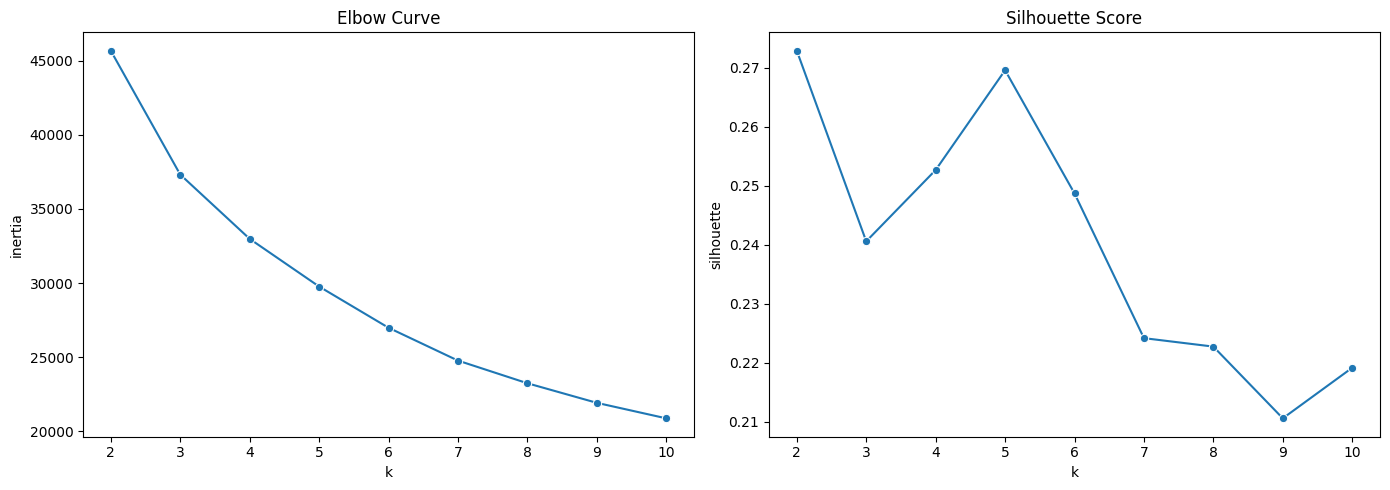

Best K by silhouette: 2


In [5]:

fig, axes = plt.subplots(1,2, figsize=(14,5))

sns.lineplot(data=metrics, x="k", y="inertia", marker="o", ax=axes[0])
axes[0].set_title("Elbow Curve")

sns.lineplot(data=metrics, x="k", y="silhouette", marker="o", ax=axes[1])
axes[1].set_title("Silhouette Score")

plt.tight_layout()
plt.show()

best_k = int(metrics.loc[metrics["silhouette"].idxmax(), "k"])
print("Best K by silhouette:", best_k)


In [6]:

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=20)
df["kmeans_cluster"] = kmeans.fit_predict(X_scaled)

kmeans_metrics = {
    "silhouette": silhouette_score(X_scaled, df["kmeans_cluster"]),
    "davies_bouldin": davies_bouldin_score(X_scaled, df["kmeans_cluster"]),
    "calinski_harabasz": calinski_harabasz_score(X_scaled, df["kmeans_cluster"])
}
print(kmeans_metrics)


{'silhouette': 0.2728548420212427, 'davies_bouldin': 1.4025176877700078, 'calinski_harabasz': 2442.130169006488}


## Compare Agglomerative and DBSCAN

In [7]:

agg = AgglomerativeClustering(n_clusters=best_k)
agg_labels = agg.fit_predict(X_scaled)

agg_metrics = {
    "silhouette": silhouette_score(X_scaled, agg_labels),
    "davies_bouldin": davies_bouldin_score(X_scaled, agg_labels),
    "calinski_harabasz": calinski_harabasz_score(X_scaled, agg_labels)
}

dbscan = DBSCAN(eps=0.8, min_samples=10)
db_labels = dbscan.fit_predict(X_scaled)

db_metrics = {}
mask = db_labels != -1

if mask.sum() > 1 and len(set(db_labels[mask])) > 1:
    db_metrics = {
        "silhouette": silhouette_score(X_scaled[mask], db_labels[mask]),
        "davies_bouldin": davies_bouldin_score(X_scaled[mask], db_labels[mask]),
        "calinski_harabasz": calinski_harabasz_score(X_scaled[mask], db_labels[mask])
    }

comparison = pd.DataFrame(
    [kmeans_metrics, agg_metrics, db_metrics],
    index=["KMeans","Agglomerative","DBSCAN"]
)
display(comparison)


,silhouette,davies_bouldin,calinski_harabasz
KMeans,0.272855,1.402518,2442.130169
Agglomerative,0.238538,1.404537,1967.741837
DBSCAN,0.078104,1.140474,473.818792


## Cluster profiling

In [8]:

profile = (
    df.groupby("kmeans_cluster")[SEGMENT_FEATURES]
      .mean()
      .sort_values("monetary", ascending=False)
)

display(profile)


,recency,frequency,monetary,average_order_value,customer_lifetime,unique_products,total_quantity,avg_purchase_interval,median_purchase_interval,weekend_purchase_ratio,avg_monthly_orders
kmeans_cluster,,,,,,,,,,,
1,90.303783,11.717616,6122.516130,511.736770,449.683607,146.998089,3711.131066,66.247592,52.818686,0.150311,1.447031
0,290.433609,1.933149,509.915954,292.290851,131.249310,29.818461,294.250537,115.028464,104.959522,0.139706,1.045610


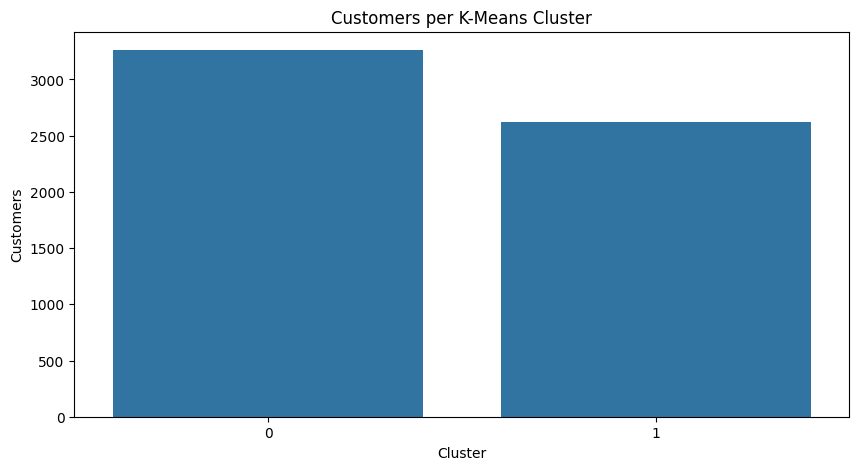

In [9]:

sizes = df["kmeans_cluster"].value_counts().sort_index()

plt.figure(figsize=(10,5))
sns.barplot(x=sizes.index.astype(str), y=sizes.values)
plt.title("Customers per K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Customers")
plt.show()


## Assign business segment names

Do not use cluster IDs from an example.

Inspect the profile above and decide which cluster is:

- Champions
- Loyal Customers
- Potential Loyalists
- At Risk
- Low Value / Other

Then create the mapping below.


In [ ]:

# Example template — REPLACE IDs after inspecting `profile`.
#
# segment_mapping = {
#     0: "Champions",
#     1: "Loyal Customers",
#     2: "Potential Loyalists",
#     3: "At Risk",
#     4: "Low Value"
# }
#
# df["segment"] = df["kmeans_cluster"].map(segment_mapping)
# df.to_csv(DATA, index=False)
